In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

2026-11-22 23:05:42.579113: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-22 23:05:42.579302: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-22 23:05:42.617305: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
# Data PBL menggantikan data rumah dummy
data = pd.read_csv('../../dataset_pbl/cafes.csv')
X = data[['review_count']]
y = data[['rating']]
scaler = StandardScaler()
X = scaler.fit_transform(X)
y = scaler.fit_transform(y)
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2)

In [3]:
# Model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)
])

In [4]:
bobot_awal = model.get_weights()

In [5]:
model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=100)

Epoch 1/100


I0000 00:00:1795363559.384276    1719 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


8/8 [==============================] - 3s 9ms/step - loss: 1.4552
Epoch 2/100
8/8 [==============================] - 0s 8ms/step - loss: 1.4133
Epoch 3/100
8/8 [==============================] - 0s 8ms/step - loss: 1.3777
Epoch 4/100
8/8 [==============================] - 0s 9ms/step - loss: 1.3445
Epoch 5/100
8/8 [==============================] - 0s 8ms/step - loss: 1.3127
Epoch 6/100
8/8 [==============================] - 0s 9ms/step - loss: 1.2814
Epoch 7/100
8/8 [==============================] - 0s 9ms/step - loss: 1.2587
Epoch 8/100
8/8 [==============================] - 0s 8ms/step - loss: 1.2311
Epoch 9/100
8/8 [==============================] - 0s 8ms/step - loss: 1.2107
Epoch 10/100
8/8 [==============================] - 0s 8ms/step - loss: 1.1877
Epoch 11/100
8/8 [==============================] - 0s 8ms/step - loss: 1.1716
Epoch 12/100
8/8 [==============================] - 0s 8ms/step - loss: 1.1549
Epoch 13/100
8/8 [==============================] - 0s 9ms/step - loss: 1

In [6]:
hasil = [(0.001, model.history.history['loss'][-1])]

In [7]:
# Evaluasi
print("Prediksi:", model.predict(X_test))

2/2 [==============================] - 0s 5ms/step
Prediksi: [[ 0.15687831]
 [-0.13220204]
 [ 0.20942326]
 [-0.32715282]
 [ 0.17877205]
 [ 0.23569573]
 [ 0.21915378]
 [ 0.18752955]
 [ 0.01919098]
 [-0.31862023]
 [-0.04542824]
 [-0.09591366]
 [-0.29173422]
 [ 0.15444566]
 [-0.299604  ]
 [-0.32721007]
 [-0.33230326]
 [ 0.07124944]
 [ 0.15103997]
 [ 0.1661223 ]
 [ 0.13011931]
 [ 0.23229004]
 [-0.30524355]
 [ 0.15201302]
 [ 0.15249954]
 [ 0.17050107]
 [-0.3332761 ]
 [-0.33041322]
 [-0.22861984]
 [-0.24468948]
 [ 0.23472269]
 [-0.0289409 ]
 [ 0.22353257]
 [-0.1603239 ]
 [-0.27252978]
 [ 0.2133155 ]
 [-0.12588897]
 [-0.25512224]
 [ 0.17682593]
 [ 0.21964033]
 [ 0.23180355]
 [ 0.03378682]
 [-0.32824016]
 [ 0.23610587]
 [ 0.20893674]
 [ 0.22791131]
 [ 0.1958005 ]
 [ 0.21428855]
 [ 0.21915378]
 [ 0.19871967]
 [ 0.22839786]
 [ 0.18217771]
 [ 0.23645993]
 [-0.30524355]
 [ 0.18266426]
 [ 0.05519404]
 [-0.27279466]
 [ 0.1967736 ]
 [-0.32595402]
 [ 0.00848737]
 [-0.25773877]]


In [8]:
for learning_rate in [0.01, 0.1]:
    model = tf.keras.Sequential([
        tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
        tf.keras.layers.Dense(1)
    ])
    model.set_weights(bobot_awal)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate), loss='mse')
    h = model.fit(X_train, y_train, epochs=100)
    hasil.append((learning_rate, h.history['loss'][-1]))

print(f"{'Learning rate':>14} {'Loss latih akhir':>18}")
for learning_rate, loss_akhir in hasil:
    print(f"{learning_rate:>14.3f} {loss_akhir:>18.6f}")

Epoch 1/100
8/8 [==============================] - 1s 7ms/step - loss: 1.3264
Epoch 2/100
8/8 [==============================] - 0s 8ms/step - loss: 1.1131
Epoch 3/100
8/8 [==============================] - 0s 6ms/step - loss: 0.9657
Epoch 4/100
8/8 [==============================] - 0s 7ms/step - loss: 0.9173
Epoch 5/100
8/8 [==============================] - 0s 5ms/step - loss: 0.8831
Epoch 6/100
8/8 [==============================] - 0s 6ms/step - loss: 0.8906
Epoch 7/100
8/8 [==============================] - 0s 7ms/step - loss: 0.8822
Epoch 8/100
8/8 [==============================] - 0s 6ms/step - loss: 0.8802
Epoch 9/100
8/8 [==============================] - 0s 6ms/step - loss: 0.8802
Epoch 10/100
8/8 [==============================] - 0s 6ms/step - loss: 0.8760
Epoch 11/100
8/8 [==============================] - 0s 6ms/step - loss: 0.8741
Epoch 12/100
8/8 [==============================] - 0s 5ms/step - loss: 0.8723
Epoch 13/100
8/8 [==============================] - 0s 6ms/st

In [9]:
# MLP regresi (Keras)
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

In [10]:
# Bagian kedua - Regresi beberapa fitur PBL menggantikan Boston
data = pd.read_csv('../../dataset_pbl/cafes.csv')
X = data[['latitude','longitude','review_count']].to_numpy()
y = data['rating'].to_numpy()
scaler = StandardScaler()
Xs = scaler.fit_transform(X)
X_train, X_val, y_train, y_val = train_test_split(Xs,y,test_size=0.2,random_state=42)

In [11]:
# 3. Build model
model = Sequential([
Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
Dense(32, activation='relu'),
Dense(1)
])
model.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])

In [12]:
# 4. Train
h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=32, verbose=0)

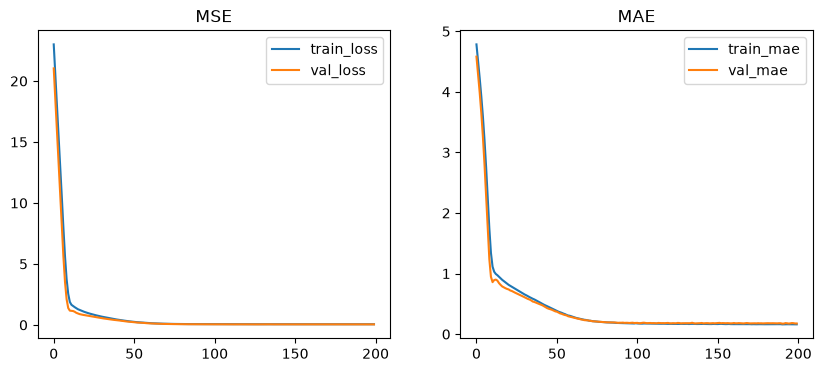

2/2 [==============================] - 0s 6ms/step
RMSE: 0.21084485037411074


In [13]:
# 5. Plot
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(h.history['loss'], label='train_loss'); plt.plot(h.history['val_loss'], label='val_loss'); plt.legend(); plt.title('MSE')
plt.subplot(1,2,2); plt.plot(h.history['mae'], label='train_mae'); plt.plot(h.history['val_mae'], label='val_mae'); plt.legend(); plt.title('MAE')
plt.show()

from sklearn.metrics import mean_squared_error
pred = model.predict(X_val)
print('RMSE:', np.sqrt(mean_squared_error(y_val, pred)))